# 02d Evolución de las reseñas de los 100 juegos con más recomendaciones

**Documento relacionado:** [`docs/03-analisis-exploratorio.md`](../docs/03-analisis-exploratorio.md)

**Origen:** convertido del script `evolucion_top100_recomendaciones.py`, que se eliminó de `borradores/` al pasar a este notebook.

## Objetivo

Ver cómo evolucionaron, de noviembre de 2021 a octubre de 2026, las reseñas mensuales de los 100 juegos con más recomendaciones al corte del dataset. El dataset es una sola fotografía, así que la historia se obtiene del histograma mensual de reseñas que publica Steam (`appreviewhistogram`).

| Entradas | Salidas |
|---|---|
| `steam_games.csv.gz` (ranking); historial de Steam guardado en `data/interim/hist.csv` | `reports/figures/evolucion_top100_mapa_calor.png`, `reports/figures/evolucion_top10_y_total.png`, `reports/metrics/resenas_mensuales_top100.csv` |

## Configuración

`descargarHistorial = False` reutiliza `data/interim/top100.csv` y `hist.csv` (descargados el 2026-11-22) para que las gráficas sean reproducibles. Con `True` se vuelve a consultar Steam (≈ 1 minuto) y los datos cambian.

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Rutas del repositorio (el notebook vive en notebooks/)
rootDir = Path('..').resolve()
figuresDir = rootDir / 'reports' / 'figures'
metricsDir = rootDir / 'reports' / 'metrics'
processedDir = rootDir / 'data' / 'processed'
interimDir = rootDir / 'data' / 'interim'
for outPath in (figuresDir, metricsDir, processedDir, interimDir):
    outPath.mkdir(parents=True, exist_ok=True)

# Datos: versión del 2026-11-19. Se busca primero la variable de entorno STEAM_GAMES_CSV,
# luego data/raw/ y por último la carpeta Proyecto Final/Datos (fuera del repositorio).
dataCandidates = [
    Path(os.environ['STEAM_GAMES_CSV']) if 'STEAM_GAMES_CSV' in os.environ else None,
    rootDir / 'data' / 'raw' / 'steam_games.csv.gz',
    rootDir / 'data' / 'raw' / 'steam_games.csv',
    rootDir.parents[1] / 'Datos' / 'steam_games.csv.gz',
]
dataPath = next((p for p in dataCandidates if p is not None and p.exists()), None)
if dataPath is None:
    raise FileNotFoundError('No se encontró steam_games.csv(.gz); colócalo en data/raw/ o define STEAM_GAMES_CSV')
print('Datos:', dataPath.name)

snapshotDate = pd.Timestamp('2026-11-19')   # fecha de corte de la versión del dataset

# Fuente latina + respaldo CJK (macOS: Hiragino/PingFang; Linux: Noto CJK). Solo las instaladas.
installedFonts = {f.name for f in fm.fontManager.ttflist}
cjkFonts = [f for f in ('Hiragino Sans GB', 'PingFang SC', 'Arial Unicode MS', 'Noto Sans CJK SC', 'Noto Sans CJK JP')
            if f in installedFonts]
plt.rcParams['font.family'] = ['DejaVu Sans'] + cjkFonts
pd.set_option('display.width', 200)

import time
import matplotlib.colors as mcolors
import matplotlib.dates as mdates

descargarHistorial = False
top100Path = interimDir / 'top100.csv'
histPath = interimDir / 'hist.csv'
if not (top100Path.exists() and histPath.exists()):
    descargarHistorial = True
print('Descargar historial de Steam:', descargarHistorial)

Datos: steam_games.csv.gz
Descargar historial de Steam: False


## Paso 1: ranking y descarga del historial

Se toman los 200 juegos con más `recommendations` y se eliminan duplicados por nombre (por ejemplo, ediciones de Rainbow Six Siege) y el «Friend's Pass» de It Takes Two, que no tiene reseñas propias. Quedan los primeros 100.

In [2]:
if descargarHistorial:
    import requests

    rankDf = pd.read_csv(dataPath, usecols=['app_id', 'name', 'recommendations', 'positive', 'negative', 'release_date'])
    rankDf['reviewCount'] = rankDf['positive'] + rankDf['negative']
    candidateDf = rankDf.nlargest(200, 'recommendations').copy()
    candidateDf['nameKey'] = candidateDf['name'].str.strip().str.lower()
    candidateDf = candidateDf[candidateDf['app_id'] != 2995920]  # It Takes Two Friend's Pass
    candidateDf = (candidateDf.sort_values('reviewCount', ascending=False).drop_duplicates('nameKey')
                   .sort_values('recommendations', ascending=False))
    topDf = candidateDf.head(100).reset_index(drop=True)
    topDf['rank'] = topDf.index + 1
    topDf.rename(columns={'reviewCount': 'n', 'nameKey': 'key'}).to_csv(top100Path, index=False)

    histRows = []
    for appId in topDf['app_id']:
        for attempt in range(3):
            try:
                url = f'https://store.steampowered.com/appreviewhistogram/{appId}?l=english&review_score_preference=0'
                results = requests.get(url, timeout=20).json()['results']
                for rollup in results['rollups']:
                    histRows.append((appId, rollup['date'], rollup['recommendations_up'], rollup['recommendations_down']))
                break
            except Exception:
                time.sleep(2)
        time.sleep(0.3)
    pd.DataFrame(histRows, columns=['app_id', 'ts', 'up', 'down']).to_csv(histPath, index=False)

topDf = pd.read_csv(top100Path)
histDf = pd.read_csv(histPath)
print(f"{histDf['app_id'].nunique()} juegos con historial · {len(histDf):,} registros")
topDf[['rank', 'name', 'recommendations']].head(20)

100 juegos con historial · 10,906 registros


,rank,name,recommendations
0,1,Counter-Strike 2,5179195.0
1,2,Grand Theft Auto V Legacy,1888724.0
2,3,PUBG: BATTLEGROUNDS,1762310.0
3,4,Tom Clancy's Rainbow Six Siege,1247987.0
4,5,Terraria,1227375.0
5,6,Rust,1155024.0
6,7,Garry's Mod,1080489.0
7,8,Wallpaper Engine,934184.0
8,9,Cyberpunk 2077,901148.0
9,10,Stardew Valley,883813.0


## Paso 2: matriz juego × mes

Antes del primer mes con datos el valor queda vacío (el juego aún no salía); después, un mes sin datos cuenta como 0.

In [3]:
histDf['month'] = pd.to_datetime(histDf['ts'], unit='s').dt.to_period('M').dt.to_timestamp()
histDf = histDf.groupby(['app_id', 'month'], as_index=False)[['up', 'down']].sum()
histDf['total'] = histDf['up'] + histDf['down']
monthRange = pd.date_range('2021-11-01', '2026-10-01', freq='MS')
monthlyMatrix = (histDf.pivot(index='app_id', columns='month', values='total')
                 .reindex(index=topDf['app_id'], columns=monthRange))
for appId in monthlyMatrix.index:
    rowValues = monthlyMatrix.loc[appId]
    firstMonth = rowValues.first_valid_index()
    if firstMonth is not None:
        monthlyMatrix.loc[appId, rowValues.index >= firstMonth] = rowValues[rowValues.index >= firstMonth].fillna(0)
monthlyMatrix.to_csv(metricsDir / 'resenas_mensuales_top100.csv')

gameLabels = [f'{rank}. {name}' for rank, name in
              zip(topDf['rank'], topDf['name'].str.replace('™', '').str.replace('®', ''))]
monthlyMatrix.iloc[:5, -6:]

,2026-05-01,2026-06-01,2026-07-01,2026-08-01,2026-09-01,2026-10-01
app_id,,,,,,
730,75504.0,73021.0,79710.0,82960.0,75992.0,75663.0
271590,5431.0,6224.0,8097.0,5568.0,5174.0,4970.0
578080,12822.0,12207.0,12993.0,12725.0,37411.0,11584.0
359550,11393.0,12029.0,10608.0,12919.0,13289.0,11006.0
105600,6992.0,7399.0,9326.0,9125.0,7968.0,7826.0


## Mapa de calor

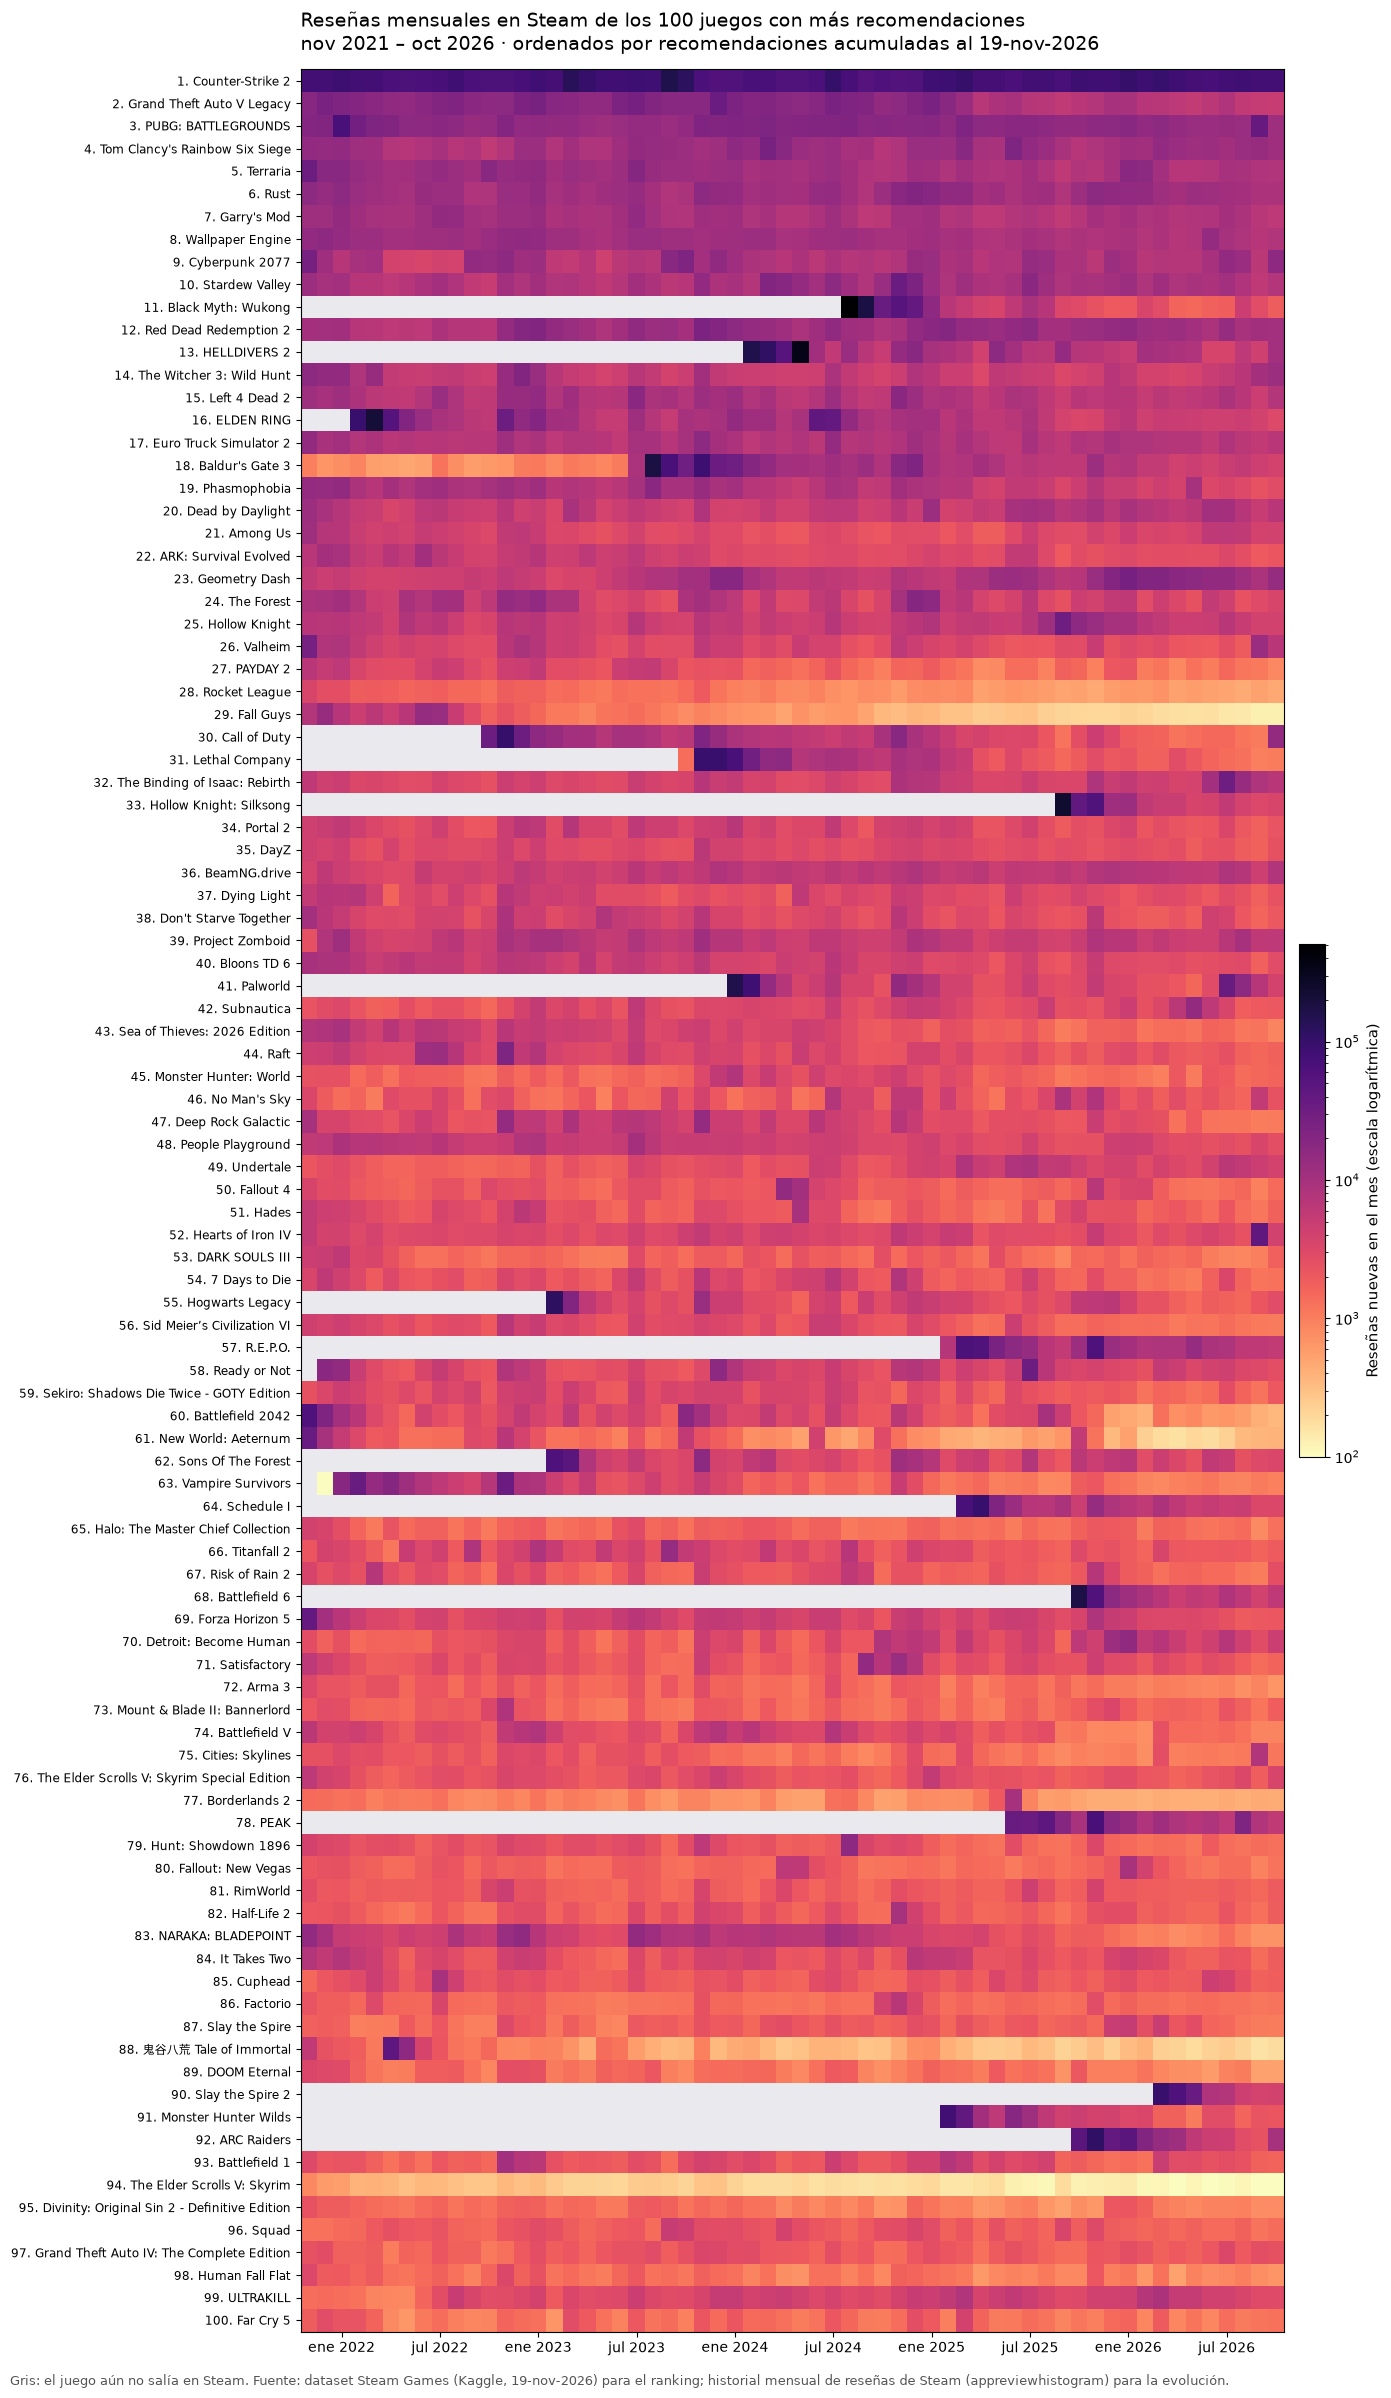

In [4]:
fig, ax = plt.subplots(figsize=(14, 24))
heatCmap = plt.get_cmap('magma_r').copy()
heatCmap.set_bad('#e9e9ee')
heatImage = ax.imshow(monthlyMatrix.values + 0.0, aspect='auto', cmap=heatCmap,
                      norm=mcolors.LogNorm(vmin=100, vmax=monthlyMatrix.max().max()), interpolation='nearest')
ax.set_yticks(range(100))
ax.set_yticklabels(gameLabels, fontsize=8.5)
tickIdx = [i for i, m in enumerate(monthRange) if m.month in (1, 7)]
ax.set_xticks(tickIdx)
ax.set_xticklabels([monthRange[i].strftime('%b %Y').replace('Jan', 'ene').replace('Jul', 'jul') for i in tickIdx],
                   fontsize=10)
ax.set_xticks(np.arange(-.5, 60, 1), minor=True)
ax.tick_params(which='minor', length=0)
colorBar = fig.colorbar(heatImage, ax=ax, fraction=0.025, pad=0.015)
colorBar.set_label('Reseñas nuevas en el mes (escala logarítmica)', fontsize=11)
ax.set_title('Reseñas mensuales en Steam de los 100 juegos con más recomendaciones\n'
             'nov 2021 – oct 2026 · ordenados por recomendaciones acumuladas al 19-nov-2026',
             fontsize=14, loc='left', pad=14)
fig.text(0.01, 0.004, 'Gris: el juego aún no salía en Steam. Fuente: dataset Steam Games (Kaggle, 19-nov-2026) para el '
         'ranking; historial mensual de reseñas de Steam (appreviewhistogram) para la evolución.', fontsize=9, color='#555')
fig.tight_layout(rect=(0, 0.01, 1, 1))
fig.savefig(figuresDir / 'evolucion_top100_mapa_calor.png', dpi=130)
plt.show()

## Top 10 y total del top 100

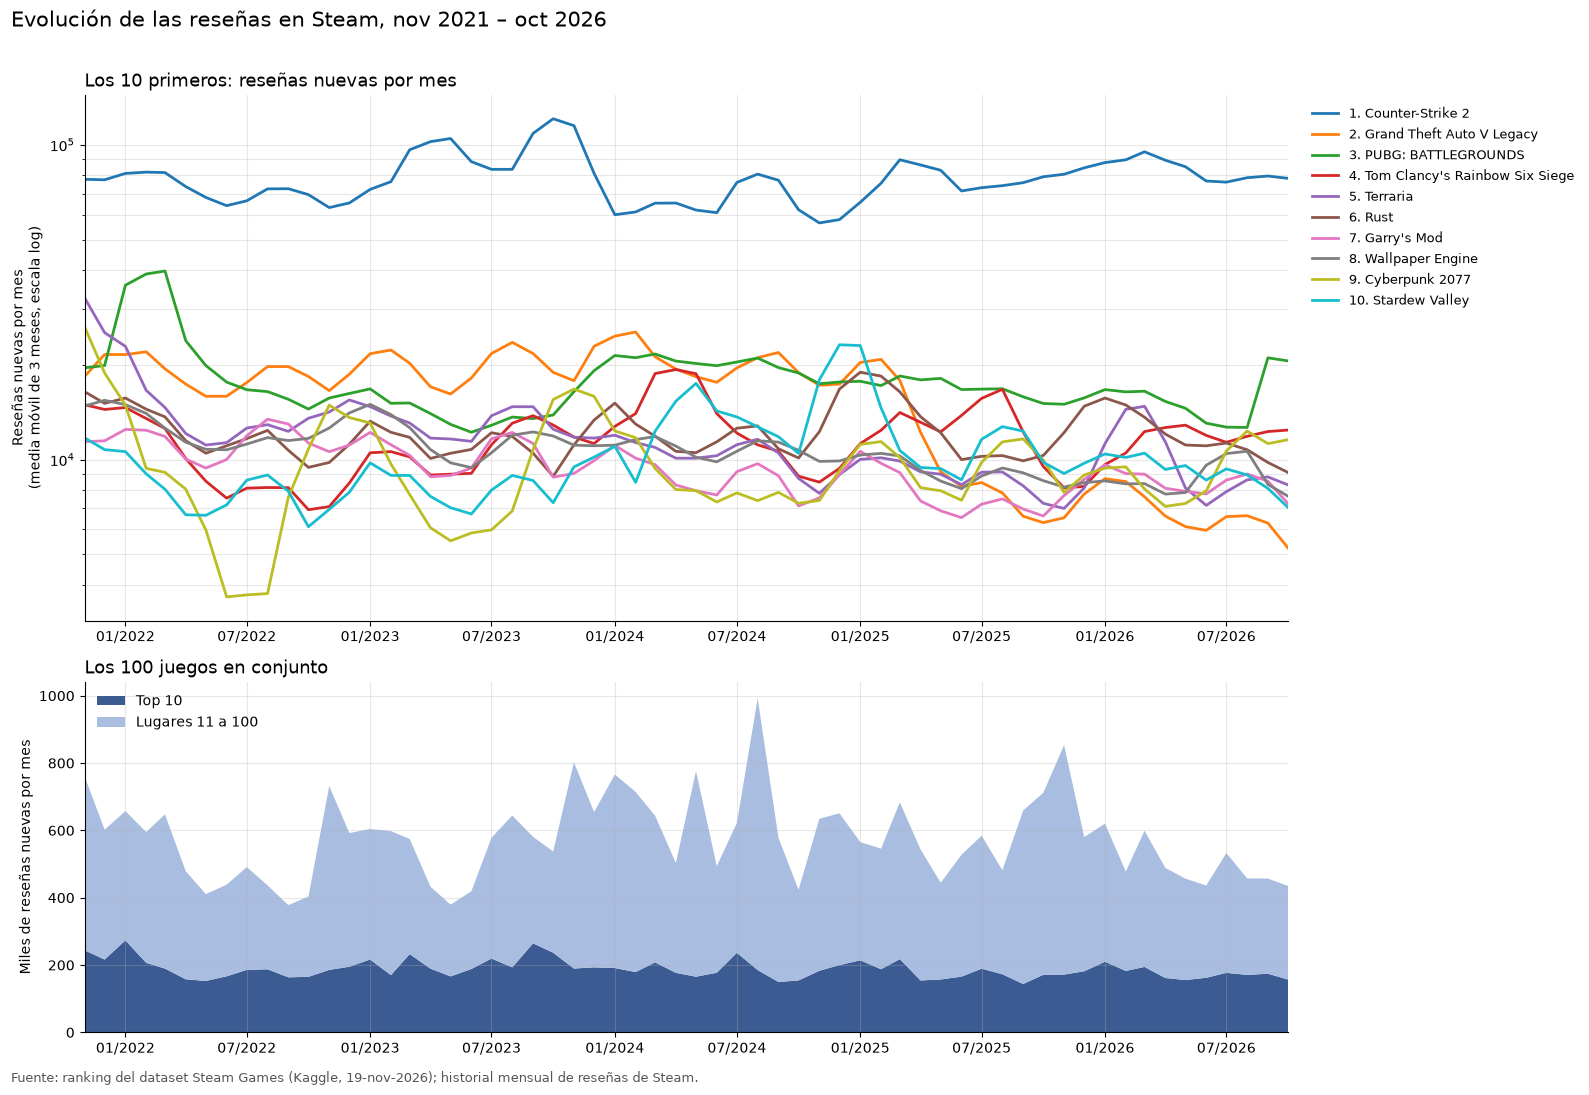

In [5]:
fig, (axTop, axTotal) = plt.subplots(2, 1, figsize=(16, 11), gridspec_kw={'height_ratios': [1.5, 1]})
lineColors = plt.get_cmap('tab10').colors
for i, (appId, gameLabel) in enumerate(zip(topDf['app_id'][:10], gameLabels[:10])):
    smoothed = monthlyMatrix.loc[appId].rolling(3, min_periods=1).mean()
    axTop.plot(monthRange, smoothed, color=lineColors[i], lw=2, label=gameLabel)
axTop.set_yscale('log')
axTop.set_ylabel('Reseñas nuevas por mes\n(media móvil de 3 meses, escala log)')
axTop.set_title('Los 10 primeros: reseñas nuevas por mes', loc='left', fontsize=13)
axTop.legend(fontsize=9.5, frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1))
axTop.grid(alpha=.3, which='both')

totalMonthly = monthlyMatrix.sum()
top10Monthly = monthlyMatrix.iloc[:10].sum()
axTotal.stackplot(monthRange, top10Monthly / 1e3, (totalMonthly - top10Monthly) / 1e3,
                  colors=['#3b5b92', '#a9bde0'], labels=['Top 10', 'Lugares 11 a 100'])
axTotal.set_ylabel('Miles de reseñas nuevas por mes')
axTotal.set_title('Los 100 juegos en conjunto', loc='left', fontsize=13)
axTotal.legend(loc='upper left', frameon=False)
axTotal.grid(alpha=.3)
for ax in (axTop, axTotal):
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
    ax.set_xlim(monthRange[0], monthRange[-1])
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Evolución de las reseñas en Steam, nov 2021 – oct 2026', fontsize=15, x=0.01, ha='left')
fig.text(0.01, 0.005, 'Fuente: ranking del dataset Steam Games (Kaggle, 19-nov-2026); historial mensual de reseñas de Steam.',
         fontsize=9, color='#555')
fig.tight_layout(rect=(0, 0.015, 1, 0.97))
fig.savefig(figuresDir / 'evolucion_top10_y_total.png', dpi=130)
plt.show()

## Concentración de reseñas en el último año

In [6]:
nameById = dict(zip(topDf['app_id'], topDf['name']))
print(totalMonthly.iloc[[0, 12, 24, 36, 48, 59]].rename('reseñas del top 100').to_string())
lastYearShare = (monthlyMatrix.iloc[:, -12:].sum(axis=1) / monthlyMatrix.sum(axis=1)).sort_values()
lastYearShare.tail(8).rename(index=nameById).round(3).to_frame('proporción en los últimos 12 meses')

2021-11-01    761229.0
2022-11-01    731722.0
2023-11-01    802222.0
2024-11-01    634529.0
2025-11-01    853401.0
2026-10-01    435024.0


,proporción en los últimos 12 meses
app_id,
The Binding of Isaac: Rebirth,0.354
Detroit: Become Human,0.355
Geometry Dash,0.377
R.E.P.O.,0.427
Battlefield™ 6,0.447
PEAK,0.566
ARC Raiders,0.855
Slay the Spire 2,1.000


## Conclusiones del notebook

- Varios juegos de la lista salieron dentro de estos 5 años (por ejemplo, Elden Ring, Baldur's Gate 3, Palworld y ARC Raiders). Casi todos tienen un pico muy fuerte el mes de salida y luego bajan: buena parte de las reseñas de un éxito llega en los primeros meses.
- Los veteranos se mantienen: Counter-Strike 2 recibe entre 54,000 y 158,000 reseñas al mes, varias veces más que cualquier otro juego.
- El total mensual del top 100 no crece con el tiempo; oscila entre 380,000 y 990,000 reseñas, con picos cuando sale un juego grande.
- Las franjas grises corresponden solo a los meses previos al lanzamiento de cada juego (por ejemplo, Black Myth: Wukong desde agosto de 2024, HELLDIVERS 2 desde febrero de 2024 y Palworld desde enero de 2024); se verificó contra `hist.csv`.